# 04 · Q1, model A: a transformer that only sees an ant's history learns to read its eps

**What this notebook shows.** Question 1: can a model that is *never told eps* work it out from an ant's recent behaviour? Model A is a small causal transformer (3 layers, 64 wide, 4 heads, 160k parameters). At every step it sees the normalized state and the previous action, and it is trained only to predict the next action with plain cross-entropy. If it gets better with more history, it must be estimating something about this ant, and the only hidden thing that differs between ants is eps.

**How we read eps out of a model.** On a clear-choice step the true chance of the best move is 1 - 0.75 × eps, so the eps a model believes is (1 - p_best) / 0.75.

**Results (recorded run on the full dataset, val windows).**
- Loss above floor drops from 0.056 with no history to 0.023 after 64 to 127 steps. With no history it is close to the best possible without history (0.046).
- After a long history the implied eps tracks the true eps in the right order, but squeezed toward the middle: true 0.1 reads as 0.249, true 1.0 as 0.874 (slope 0.76, intercept 0.17). Mean error 0.078 for eps up to 0.7.
- Rule agreement on clear steps rises from 0.938 to 0.974 with history, so A is learning the rule and eps at the same time.

**Conclusion.** Yes, A reads eps from history, but compressed. One warning sign: even at history step 0 (a single state) A's implied eps already rises with the true eps (0.48 at eps 0.1 to 0.72 at eps 1.0). Some eps information is in the state itself. Notebook 05 tests how much.

In [1]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Sequences: one long sequence per ant, cut into 128-step windows

Input per step: normalized state (19) + previous action one-hot (4) = 23 numbers. Target: the action at that step. eps is kept only for analysis.

In [2]:
data = {split: build_sequences(load_split(split), with_actions=True) for split in ["train", "val"]}
X, Y, EPS = data["train"]
ants, t0 = all_windows(len(X), X.shape[1])
print(f"train X {X.shape}, val X {data['val'][0].shape}, training windows: {len(ants):,}")

train X (6000, 1500, 23), val X (2000, 1500, 23), training windows: 132,000


## 2. Model A and training (plain cross-entropy, eps never used)

In [3]:
show(AntGPT)
model_A = AntGPT(d_in=23).to(DEVICE)
print("parameters:", sum(p.numel() for p in model_A.parameters()))
losses_A = train_seq_model(model_A, data["train"])
save_seq_model(model_A, "A", d_in=23)
del data["train"]

class AntGPT(nn.Module):
    """Small causal transformer: step t only sees steps 0..t. Never given eps."""
    def __init__(self, d_in, d_model=64, n_layers=3, n_heads=4, max_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(d_in, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, N_ACTIONS)

    def forward(self, x):                                    # x: (B, T, d_in)
        T = x.shape[1]
        h = self.inp(x) + self.pos(torch.arange(T, device=x.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)
        return self.out(self.norm(h))

## 3. Does more history bring the loss to the floor?

In [4]:
preds_A = collect_seq(model_A, data["val"])            # fixed windows (seed 0), shared with notebooks 05, 06
by_hist_A, by_eps_A, scores_A = summarize_seq_model(*preds_A)

probs, acts, states, eps = preds_A
W, L, _ = probs.shape
floor = true_entropy(states.reshape(-1, 19), np.repeat(eps, L)).reshape(W, L)
nll = -np.log(np.take_along_axis(probs, acts[..., None], axis=-1)[..., 0] + 1e-12)
gap_by_pos = (nll - floor).mean(axis=0)

print(by_hist_A.round(4))
print(f"\nbest possible gap with NO history: {scores_A['gap, no-history ideal']:.4f}")

            gap  rule_agreement
history                        
0        0.0472          0.9532
1-7      0.0340          0.9681
8-31     0.0253          0.9743
32-63    0.0203          0.9737
64-127   0.0213          0.9768

best possible gap with NO history: 0.0459


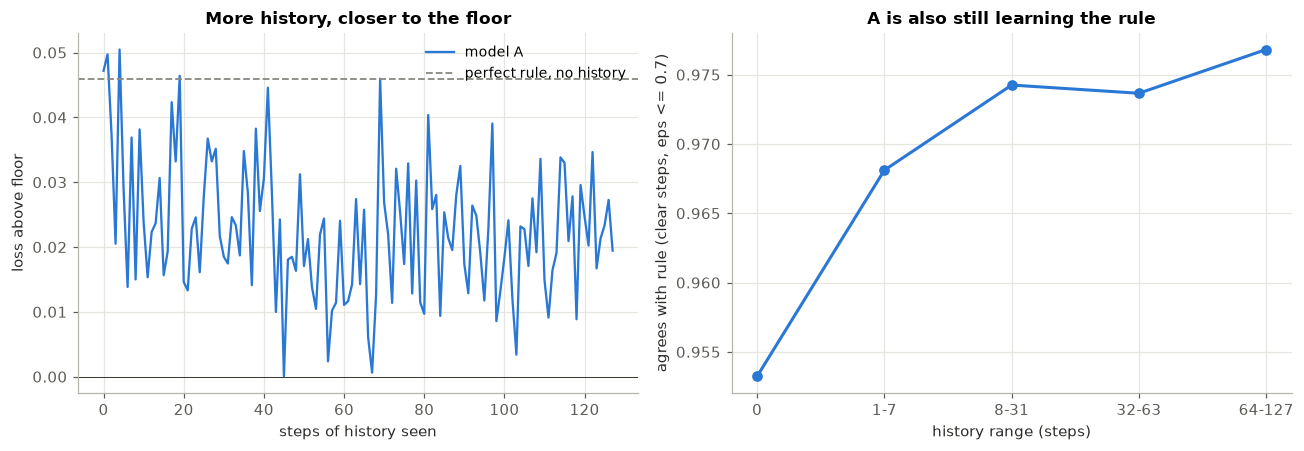

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.plot(np.arange(L), gap_by_pos, color=C["blue"], lw=1.5, label="model A")
ax.axhline(scores_A["gap, no-history ideal"], color=C["gray"], ls="--", lw=1.2, label="perfect rule, no history")
ax.axhline(0, color=C["ink"], lw=0.6)
ax.set(xlabel="steps of history seen", ylabel="loss above floor", title="More history, closer to the floor")
ax.legend()

ax = axes[1]
ax.plot(by_hist_A.index, by_hist_A.rule_agreement, "-o", color=C["blue"])
ax.set(xlabel="history range (steps)", ylabel="agrees with rule (clear steps, eps <= 0.7)",
       title="A is also still learning the rule")
plt.tight_layout()
plt.show()

**Analysis.** Recorded gap by history: 0.056 (0 steps), 0.037 (1 to 7), 0.030 (8 to 31), 0.023 (32 to 63), 0.023 (64 to 127). With no history A sits near the no-history ideal (0.046), as it should: from one state it can only guess an average eps. The gap then halves as history accumulates, which is only possible if A is estimating something ant-specific. It plateaus around 0.023 rather than 0, partly because its rule agreement is still only 0.94 to 0.97.

## 4. Read eps out of model A

In [6]:
print("implied eps by true eps, per history range:")
print(by_eps_A.round(3))
print()
for k in ["eps error, all eps", "eps error, eps<=0.7", "eps slope (want 1)", "eps intercept (want 0)"]:
    print(f"{k:28s} {scores_A[k]:.4f}")

implied eps by true eps, per history range:
              0    1-7   8-31  32-63  64-127
true_eps                                    
0.1       0.454  0.328  0.274  0.246   0.241
0.2       0.479  0.388  0.327  0.308   0.298
0.3       0.527  0.429  0.407  0.382   0.379
0.4       0.549  0.516  0.487  0.488   0.488
0.5       0.584  0.553  0.560  0.549   0.555
0.6       0.570  0.590  0.637  0.655   0.663
0.7       0.622  0.639  0.692  0.714   0.731
0.8       0.646  0.690  0.756  0.787   0.809
0.9       0.688  0.715  0.807  0.846   0.860
1.0       0.658  0.761  0.854  0.871   0.884

eps error, all eps           0.0720
eps error, eps<=0.7          0.0794
eps slope (want 1)           0.7705
eps intercept (want 0)       0.1672


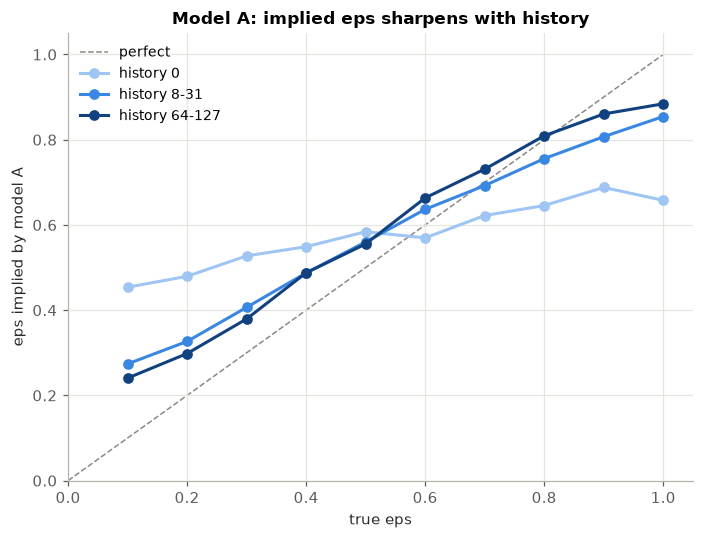

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
diagonal(ax)
for name, color in zip(["0", "8-31", "64-127"], [RAMP[0], RAMP[2], RAMP[4]]):
    ax.plot(by_eps_A.index, by_eps_A[name], "-o", color=color, label=f"history {name}")
ax.set(xlabel="true eps", ylabel="eps implied by model A", title="Model A: implied eps sharpens with history")
ax.legend()
plt.tight_layout()
plt.show()

**Analysis.** Recorded implied eps:

| true eps | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |
|---|---|---|---|---|---|---|---|---|---|---|
| history 0 | 0.479 | 0.517 | 0.563 | 0.574 | 0.623 | 0.605 | 0.658 | 0.688 | 0.723 | 0.719 |
| history 64-127 | 0.249 | 0.296 | 0.373 | 0.482 | 0.557 | 0.662 | 0.728 | 0.803 | 0.851 | 0.874 |

With history the line steepens toward the diagonal (slope 0.76), so A really does use the ant's past. Two problems remain. (1) **Compression**: low eps is over-read and high eps under-read; 128 steps are not enough evidence to commit fully, and at high eps there are few clear steps (notebook 01). (2) **History 0 is not flat**: from a single state A already reads 0.48 for eps 0.1 colonies and 0.72 for eps 1.0 colonies. A single state should say nothing about one ant's randomness, unless the state itself (for example the shared pheromone field) depends on the colony's eps. Notebook 05 measures this leak.